# 01 — Development-only Keşifsel Veri Analizi (EDA)
**Veri:** UCI Bank Marketing — yalnızca `bank-additional.csv` (4.119 gözlem, 20 girdi, ikili hedef `y`).
Bu notebook: (1) ham verinin doğru okunduğunu kontrol eder, (2) kopya kayıtları inceler, (3) %80/%20 stratified
bölünmeyi yapıp `results/dataset_split.csv` dosyasına kaydeder, (4) **yalnızca development** verisinde EDA yapar.
Bağımsız test kümesi bu notebook'ta bölünme dışında hiçbir hesaplamaya girmez.

In [1]:
# --- Ortam kurulumu (Colab'da repo klonlanır; yerelde repo kökünden çalıştırın) ---
import os, sys, platform
REPO_URL = "https://github.com/ibrahimalpsoy/ysa-midterm-bank-mlp.git"
if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists("ysa-midterm-bank-mlp"):
        os.system(f"git clone {REPO_URL}")
    os.chdir("ysa-midterm-bank-mlp")
    os.system("pip install -q -r requirements.txt")
sys.path.insert(0, os.path.abspath("."))

import json, warnings
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from src import config as C
C.ensure_dirs(); C.set_global_seeds()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9})
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("BASE_SEED =", C.BASE_SEED, "| türetilmiş seedler:", C.SEEDS)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5
BASE_SEED = 31066 | türetilmiş seedler: {'python': 31066, 'numpy': 31067, 'torch': 31068, 'split': 31069, 'outer_cv': 31070, 'inner_cv': 31071, 'random_search': 31072, 'early_stop_split': 31073, 'bootstrap': 31074}


## 1. Ham verinin okunması ve doğrulanması

In [2]:
from src import data as D
if not C.RAW_CSV.exists():
    D.download_uci()          # resmî UCI zip -> data/bank-additional.csv
df = D.load_raw()
info = D.validate_raw(df)
print(info)
print("\nSütunlar ve tipler:"); print(df.dtypes.to_string())
assert "duration" in df.columns

{'n_rows': 4119, 'n_inputs': 20, 'n_numeric_after_drop': 9, 'n_categorical': 10, 'target_counts': {'no': 3668, 'yes': 451}}

Sütunlar ve tipler:
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str


**Uygulama kuralları (performans görülmeden önce sabitlendi):**
`duration` görüşme bitince bilinir → tüm modellerden çıkarılır; `y`: yes=1, no=0;
`unknown` gerçek NaN sayılmaz; `pdays=999` "daha önce temas yok" kodudur, aykırı değer olarak silinmez.

## 2. Kopya kayıt kontrolü

In [3]:
dup = D.duplicate_report(df)
print(json.dumps(dup, indent=2))

{
  "raw_exact_duplicates": 0,
  "model_input_exact_duplicates_with_target": 19,
  "model_input_feature_duplicates": 20,
  "feature_groups_with_conflicting_labels": 1,
  "n_feature_groups_size_gt1": 20
}


## 3. Stratified %80 development / %20 test bölünmesi

In [4]:
dev_idx, test_idx = D.stratified_split(df, seed=C.SEEDS["split"])
split = D.split_table(df, dev_idx, test_idx)
split.to_csv(C.RESULTS_DIR / "dataset_split.csv", index=False)
ssum = D.split_summary(df, dev_idx, test_idx)
ssum.to_csv(C.RESULTS_DIR / "split_summary.csv", index=False)
display(ssum)

# Kopya özellik vektörlerinin dev/test sınırını aşıp aşmadığı (yalnızca sayım; test etiketine bakılmaz)
X_all, _ = D.to_xy(df)
h = pd.util.hash_pandas_object(X_all, index=False).to_numpy()
dev_h, test_h = set(h[dev_idx]), h[test_idx]
cross = int(np.isin(test_h, list(dev_h)).sum())
dup["test_rows_with_identical_feature_vector_in_dev"] = cross
json.dump(dup, open(C.RESULTS_DIR / "duplicate_report.json", "w"), indent=2)
print("Dev'de birebir aynı özellik vektörüne sahip test satırı sayısı:", cross)

,subset,n,n_pos,n_neg,pos_rate
0,development,3295,361,2934,0.109560
1,test,824,90,734,0.109223
2,all,4119,451,3668,0.109493


Dev'de birebir aynı özellik vektörüne sahip test satırı sayısı: 5


## 4. Development verisi (bundan sonra yalnızca bu küme kullanılır)

In [5]:
dev = df.iloc[dev_idx].reset_index(drop=True)
dev_y = (dev["y"] == "yes").astype(int)
num, cat = D.NUMERIC_COLS, D.CATEGORICAL_COLS
print("Development:", dev.shape, "| sayısal:", len(num), "| kategorik:", len(cat), "| çıkarılan: duration")

Development: (3295, 21) | sayısal: 9 | kategorik: 10 | çıkarılan: duration


### 4.1 Özellik özeti (tür, benzersiz değer, eksik/özel kodlu değerler) — Tablo 1

In [6]:
rows = []
for c in num + cat + ["duration"]:
    s = dev[c]
    rows.append({
        "feature": c, "type": "numeric" if c in num + ["duration"] else "categorical",
        "used_in_model": c != "duration", "n_unique": s.nunique(), "n_NaN": int(s.isna().sum()),
        "n_unknown": int((s == "unknown").sum()) if c in cat else 0,
        "pct_unknown": round(100 * (s == "unknown").mean(), 2) if c in cat else 0.0,
        "n_pdays_999": int((s == 999).sum()) if c == "pdays" else 0,
    })
overview = pd.DataFrame(rows)
overview.to_csv(C.RESULTS_DIR / "eda_feature_overview.csv", index=False)
display(overview)

,feature,type,used_in_model,n_unique,n_NaN,n_unknown,pct_unknown,n_pdays_999
0,age,numeric,True,67,0,0,0.00,0
1,campaign,numeric,True,22,0,0,0.00,0
2,pdays,numeric,True,20,0,0,0.00,3167
3,previous,numeric,True,6,0,0,0.00,0
4,emp.var.rate,numeric,True,10,0,0,0.00,0
5,cons.price.idx,numeric,True,26,0,0,0.00,0
6,cons.conf.idx,numeric,True,26,0,0,0.00,0
7,euribor3m,numeric,True,217,0,0,0.00,0
8,nr.employed,numeric,True,11,0,0,0.00,0
9,job,categorical,True,12,0,36,1.09,0


### 4.2 Sınıf dağılımı

,n,pct
y,,
no (0),2934,89.04
yes (1),361,10.96


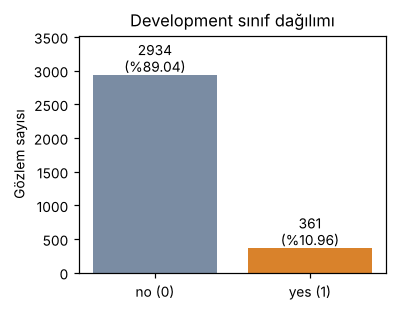

Pozitif oran = 0.1096 -> rastgele/çoğunluk modelinde AP ≈ 0.110; hep 'no' diyen model Accuracy ≈ 0.890


In [7]:
cls = dev_y.value_counts().rename(index={0: "no (0)", 1: "yes (1)"}).to_frame("n")
cls["pct"] = (100 * cls["n"] / cls["n"].sum()).round(2)
cls.to_csv(C.RESULTS_DIR / "eda_class_distribution.csv"); display(cls)
fig, ax = plt.subplots(figsize=(3.6, 2.8))
ax.bar(cls.index, cls["n"], color=["#7a8ca3", "#d9822b"])
for i, (n, p) in enumerate(zip(cls["n"], cls["pct"])):
    ax.text(i, n, f"{n}\n(%{p})", ha="center", va="bottom")
ax.set_ylabel("Gözlem sayısı"); ax.set_title("Development sınıf dağılımı"); ax.set_ylim(0, cls["n"].max() * 1.2)
fig.savefig(C.FIG_DIR / "fig02a_class_distribution.png"); plt.show()
print(f"Pozitif oran = {dev_y.mean():.4f} -> rastgele/çoğunluk modelinde AP ≈ {dev_y.mean():.3f}; "
      f"hep 'no' diyen model Accuracy ≈ {1 - dev_y.mean():.3f}")

**Yorum:** Sınıflar dengesiz (~%11 pozitif). Accuracy, hep "no" diyen modelde bile ~%89 olacağı için yanıltıcıdır;
bu nedenle birincil metrik **Average Precision (AP)**, ek olarak ROC-AUC, Sensitivity/Specificity, F1 ve Balanced Accuracy raporlanır.
AP'nin şans düzeyi pozitif sınıf oranıdır (~0.11).

### 4.3 Sayısal özellikler: tanımlayıcı istatistikler

In [8]:
dnum = dev[num].copy()
dnum["pdays (999 hariç)"] = dnum["pdays"].where(dnum["pdays"] != 999)
cols = num + ["pdays (999 hariç)"]
desc = pd.DataFrame({
    "n": dnum[cols].count(), "mean": dnum[cols].mean(), "median": dnum[cols].median(),
    "sd": dnum[cols].std(ddof=1), "q1": dnum[cols].quantile(.25), "q3": dnum[cols].quantile(.75),
    "min": dnum[cols].min(), "max": dnum[cols].max(),
})
desc["IQR"] = desc["q3"] - desc["q1"]
desc = desc[["n", "mean", "median", "sd", "IQR", "q1", "q3", "min", "max"]].round(3)
desc.to_csv(C.RESULTS_DIR / "eda_numeric_descriptives.csv"); display(desc)

,n,mean,median,sd,IQR,q1,q3,min,max
age,3295,40.085,38.000,10.371,15.000,32.000,47.000,18.000,88.000
campaign,3295,2.563,2.000,2.542,2.000,1.000,3.000,1.000,29.000
pdays,3295,960.429,999.000,191.888,0.000,999.000,999.000,1.000,999.000
previous,3295,0.189,0.000,0.537,0.000,0.000,0.000,0.000,6.000
emp.var.rate,3295,0.089,1.100,1.558,3.200,-1.800,1.400,-3.400,1.400
cons.price.idx,3295,93.580,93.749,0.575,0.919,93.075,93.994,92.201,94.767
cons.conf.idx,3295,-40.507,-41.800,4.572,6.300,-42.700,-36.400,-50.800,-26.900
euribor3m,3295,3.620,4.857,1.735,3.627,1.334,4.961,0.635,5.045
nr.employed,3295,5166.369,5191.000,73.714,129.000,5099.100,5228.100,4963.600,5228.100
pdays (999 hariç),128,6.102,6.000,3.978,4.000,3.000,7.000,1.000,21.000


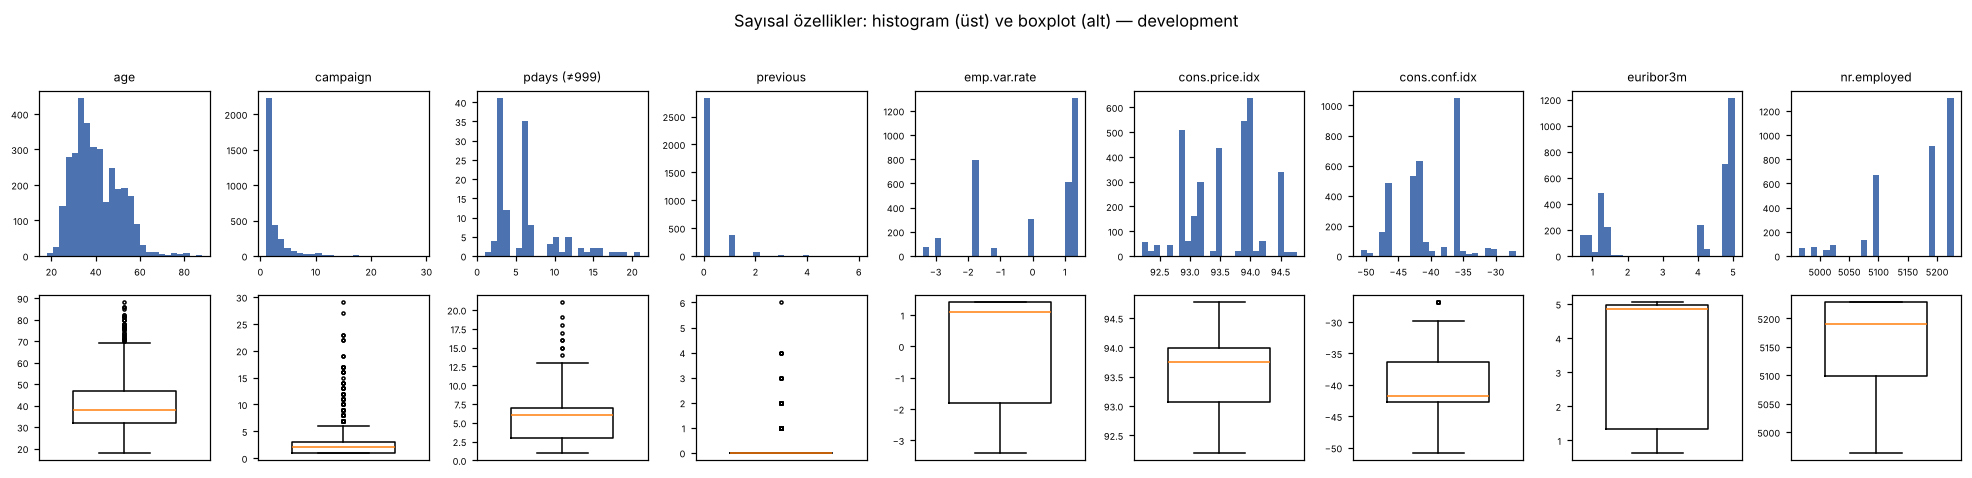

In [9]:
fig, axes = plt.subplots(2, len(num), figsize=(2.0 * len(num), 4.2))
for j, c in enumerate(num):
    v = dnum[c] if c != "pdays" else dnum["pdays (999 hariç)"].dropna()
    axes[0, j].hist(v, bins=25, color="#4c72b0"); axes[0, j].set_title(c if c != "pdays" else "pdays (≠999)", fontsize=8)
    axes[1, j].boxplot(v, widths=.6, flierprops={"markersize": 2})
    axes[1, j].set_xticks([])
    for a in axes[:, j]: a.tick_params(labelsize=6)
fig.suptitle("Sayısal özellikler: histogram (üst) ve boxplot (alt) — development", y=1.02)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "fig02b_numeric_hist_box.png"); plt.show()

### 4.4 Kategorik özellikler: frekanslar ve `unknown` kodları

,feature,n_unknown,pct_unknown
12,default,630,19.12
11,education,145,4.40
13,housing,89,2.70
14,loan,89,2.70
9,job,36,1.09
10,marital,9,0.27
15,contact,0,0.00
16,month,0,0.00
17,day_of_week,0,0.00
18,poutcome,0,0.00


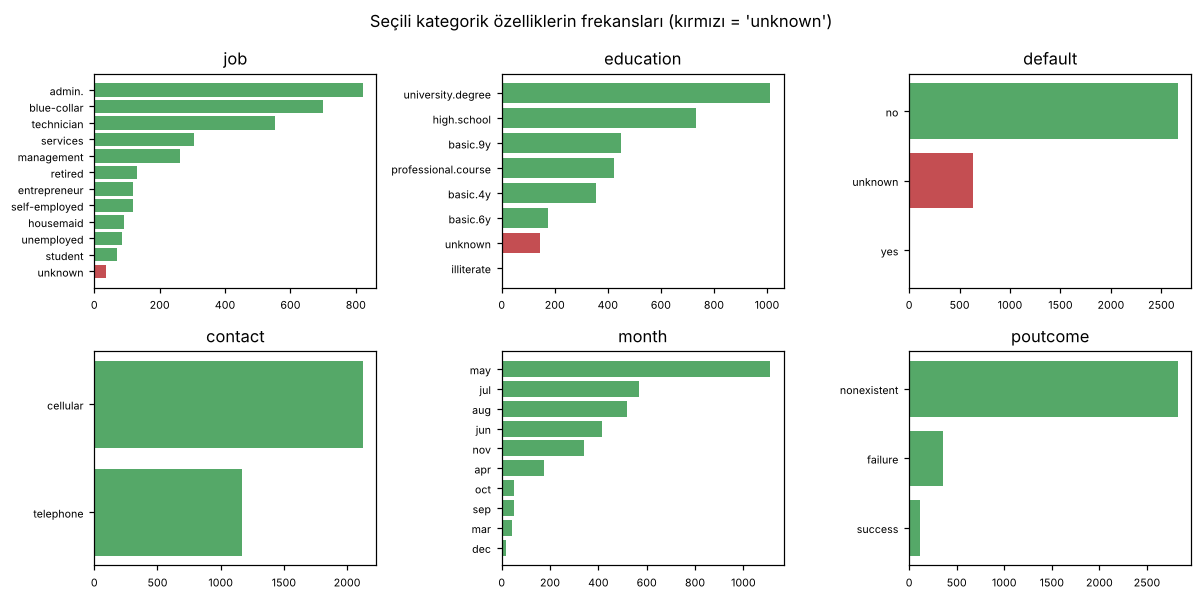

In [10]:
freq = []
for c in cat:
    vc = dev[c].value_counts()
    for k, n in vc.items():
        freq.append({"feature": c, "level": k, "n": int(n), "pct": round(100 * n / len(dev), 2)})
freq = pd.DataFrame(freq); freq.to_csv(C.RESULTS_DIR / "eda_categorical_frequencies.csv", index=False)
unk = overview.query("type=='categorical'")[["feature", "n_unknown", "pct_unknown"]]
display(unk.sort_values("n_unknown", ascending=False))
show = ["job", "education", "default", "contact", "month", "poutcome"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, c in zip(axes.ravel(), show):
    vc = dev[c].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=["#c44e52" if k == "unknown" else "#55a868" for k in vc.index[::-1]])
    ax.set_title(c); ax.tick_params(labelsize=7)
fig.suptitle("Seçili kategorik özelliklerin frekansları (kırmızı = 'unknown')"); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig02c_categorical_bars.png"); plt.show()

### 4.5 Sayısal korelasyon matrisi

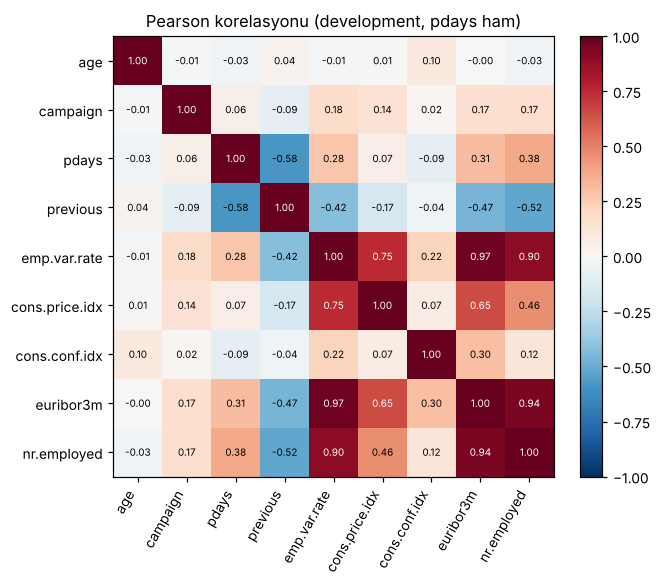

|r| > 0.8 çiftleri:
 emp.var.rate  euribor3m      0.971
              nr.employed    0.896
euribor3m     nr.employed    0.942


In [11]:
corr = dev[num].corr(method="pearson")
corr.round(3).to_csv(C.RESULTS_DIR / "eda_correlation_pearson.csv")
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > .6 else "black")
fig.colorbar(im, fraction=.046); ax.set_title("Pearson korelasyonu (development, pdays ham)")
fig.savefig(C.FIG_DIR / "fig02d_correlation.png"); plt.show()
hi = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().loc[lambda s: s.abs() > .8]
print("|r| > 0.8 çiftleri:\n", hi.round(3).to_string())

### 4.6 Seçili özelliklerin hedefe göre betimsel karşılaştırması
Yalnızca **betimsel** amaçlıdır; özellik eleme/seçme için kullanılmaz (bu bir model seçimi olurdu ve iç CV gerektirirdi).

,median | y=0,median | y=1
age,38.000,38.000
campaign,2.000,2.000
previous,0.000,0.000
euribor3m,4.857,1.262
nr.employed,5195.800,5076.200
emp.var.rate,1.100,-1.800


,feature,level,count,pos_rate
0,poutcome,failure,357,0.157
1,poutcome,nonexistent,2825,0.082
2,poutcome,success,113,0.637
3,contact,cellular,2126,0.139
4,contact,telephone,1169,0.056
5,default,no,2664,0.121
6,default,unknown,630,0.062
7,default,yes,1,0.000
8,prev_contacted (pdays≠999),no,3167,0.089
9,prev_contacted (pdays≠999),yes,128,0.617


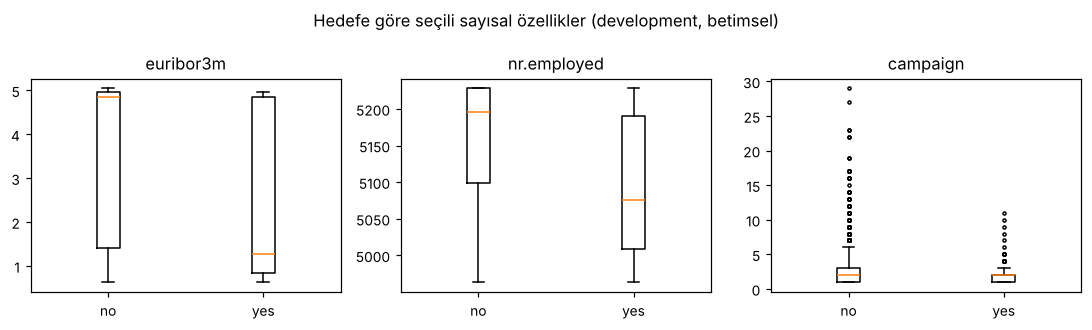

In [12]:
by_t = dev.assign(y01=dev_y).groupby("y01")[["age", "campaign", "previous", "euribor3m", "nr.employed", "emp.var.rate"]].median().T
by_t.columns = ["median | y=0", "median | y=1"]; display(by_t)
rate = []
for c in ["poutcome", "contact", "default"]:
    g = dev.assign(y01=dev_y).groupby(c)["y01"].agg(["count", "mean"]).reset_index().rename(columns={c: "level", "mean": "pos_rate"})
    g.insert(0, "feature", c); rate.append(g)
g = dev.assign(y01=dev_y, prev_contacted=(dev["pdays"] != 999).map({True: "yes", False: "no"})).groupby("prev_contacted")["y01"].agg(["count", "mean"]).reset_index().rename(columns={"prev_contacted": "level", "mean": "pos_rate"})
g.insert(0, "feature", "prev_contacted (pdays≠999)"); rate.append(g)
rate = pd.concat(rate, ignore_index=True); rate["pos_rate"] = rate["pos_rate"].round(3)
pd.concat([by_t.reset_index()], axis=0).to_csv(C.RESULTS_DIR / "eda_target_medians.csv", index=False)
rate.to_csv(C.RESULTS_DIR / "eda_target_rates.csv", index=False); display(rate)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, c in zip(axes, ["euribor3m", "nr.employed", "campaign"]):
    ax.boxplot([dev.loc[dev_y == 0, c], dev.loc[dev_y == 1, c]], tick_labels=["no", "yes"], flierprops={"markersize": 2})
    ax.set_title(c)
fig.suptitle("Hedefe göre seçili sayısal özellikler (development, betimsel)"); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig02e_target_boxplots.png"); plt.show()

### 4.7 Aykırı değer işaretleme (IQR ve yüzdelik)

In [13]:
out = []
for c in num:
    v = dev[c] if c != "pdays" else dev.loc[dev[c] != 999, c]
    q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    p1, p99 = v.quantile([.01, .99])
    out.append({"feature": c + (" (≠999)" if c == "pdays" else ""), "IQR_low": lo, "IQR_high": hi,
                "n_IQR_outliers": int(((v < lo) | (v > hi)).sum()),
                "pct_IQR_outliers": round(100 * ((v < lo) | (v > hi)).mean(), 2),
                "p01": p1, "p99": p99, "n_outside_p01_p99": int(((v < p1) | (v > p99)).sum())})
out = pd.DataFrame(out).round(3); out.to_csv(C.RESULTS_DIR / "eda_outliers.csv", index=False); display(out)

,feature,IQR_low,IQR_high,n_IQR_outliers,pct_IQR_outliers,p01,p99,n_outside_p01_p99
0,age,9.500,69.500,34,1.03,23.940,70.000,65
1,campaign,-2.000,6.000,196,5.95,1.000,13.000,32
2,pdays (≠999),-3.000,13.000,9,7.03,2.000,18.730,3
3,previous,0.000,0.000,470,14.26,0.000,3.000,14
4,emp.var.rate,-6.600,6.200,0,0.00,-3.400,1.400,0
5,cons.price.idx,91.697,95.372,0,0.00,92.201,94.473,33
6,cons.conf.idx,-52.150,-26.950,31,0.94,-50.000,-29.800,47
7,euribor3m,-4.107,10.402,0,0.00,0.668,4.968,47
8,nr.employed,4905.600,5421.600,0,0.00,4963.600,5228.100,0


**Aykırı değer politikası:** Satır silinmez. Aykırı değerler (ör. `campaign` sağ kuyruğu, `age` üst uç) gerçek ve olası değerlerdir.
Bunun yerine, yalnızca ilgili eğitim alt kümesinde öğrenilen %1–%99 yüzdelik eşiklerle **clipping**, otomatik aramada
bir hiperparametre (`clipping ∈ {yok, var}`) olarak iç CV ile değerlendirilir. `pdays=999` aykırı değil özel koddur:
`prev_contacted` göstergesine dönüştürülür, `pdays` içindeki 999 NaN yapılıp kat-içi median ile doldurulur.

**`unknown` politikası:** Varsayılan olarak ayrı kategori olarak tutulur (OneHotEncoder ile kendi sütunu olur).
Kat-içi en sık sınıf imputation alternatifi, ana 6+6 bütçenin dışında, yalnızca development iç CV'si ile
yapılan ek bir duyarlılık deneyinde (02 notebook) karşılaştırılır.

## 5. Önceden belirlenmiş deney hipotezleri

In [14]:
print(open(C.CONFIG_DIR / "hypotheses.md", encoding="utf-8").read())

# Önceden belirlenmiş deney hipotezleri

Bu hipotezler development EDA'sından sonra, nested CV çalıştırılmadan ve dış kat sonuçları görülmeden önce yazılmıştır.
Her hipotez, belirtilen karşılaştırmanın **iç CV mean AP** değerleriyle (her dış katta ve tam development'ta) test edilir.

**H1. Optimizer:** Aynı başlangıç öğrenme oranında (1e-3) SGD+Momentum (M3), AdamW'ye (M1) göre daha yavaş yakınsar.
Daha geç en iyi epoch'a ulaşır ya da 150 epoch sınırına takılır ve iç CV AP'si M1'den düşük veya eşit olur.
Adam (M2) ile AdamW (M1) arasındaki fark, weight decay = 1e-4 düzeyinde ihmal edilebilir kalır (|ΔAP| < 0.01).

**H2. Ölçekleme:** `campaign`, `previous` ve `age` sağa çarpık ve aykırı değerlidir; makroekonomik değişkenler ise az sayıda
değerde kümelenir. Bu nedenle MinMaxScaler (M4), gözlemlerin çoğunu dar bir aralığa sıkıştırarak StandardScaler'a (M1)
göre eşit veya daha düşük AP verir. Kat-içi kırpma (clipping) AP'yi belirgin biçimde düşürmez.

**H3. Kapasite:** Development'ta yakla